# Неделя 11. Деревья решений и SVM: два способа построить границу

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** посчитать уменьшение Gini, визуализировать дерево, понять margin и RBF-ядро, сравнить модели на одинаковых CV folds и открыть test после выбора.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_11_trees_svm'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'wine.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (133, 13), 'sealed_test': (45, 13)}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
sample_id,,,,,,,,,,,,,
8,14.83,1.64,2.17,14.0,97,2.8,2.98,0.29,1.98,5.20,1.08,2.85,1045
104,12.51,1.73,1.98,20.5,85,2.2,1.92,0.32,1.48,2.94,1.04,3.57,672
36,13.28,1.64,2.84,15.5,110,2.6,2.68,0.34,1.36,4.60,1.09,2.78,880


## 1. EDA: класс и масштабы признаков

На этой неделе решаем исходную задачу из **трёх классов**. Частоты классов
не одинаковы, поэтому основной критерий выбора — macro F1: каждый класс
получает одинаковый вес. Tree делит шкалы порогами, SVM чувствителен к масштабу.


,mean,std,min,max
alcohol,12.97,0.80,11.03,14.83
malic_acid,2.33,1.09,0.74,5.80
ash,2.37,0.27,1.36,3.22
alcalinity_of_ash,19.70,3.37,10.60,30.00
magnesium,100.00,14.98,70.00,162.00
total_phenols,2.28,0.63,0.98,3.88
flavanoids,1.99,0.96,0.34,3.74
nonflavanoid_phenols,0.36,0.12,0.13,0.63
proanthocyanins,1.60,0.59,0.42,3.58
color_intensity,5.01,2.37,1.28,13.00


target
0    44
1    53
2    36
Name: train_count, dtype: int64

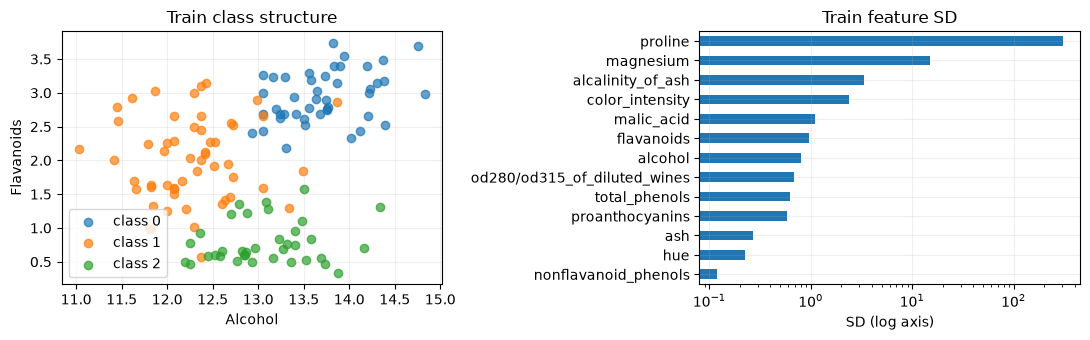

In [3]:
display(X_train.describe().T[["mean", "std", "min", "max"]].round(2))
display(y_train.value_counts().sort_index().rename("train_count"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for label in sorted(y_train.unique()):
    subset = X_train.loc[y_train == label]
    axes[0].scatter(subset.alcohol, subset.flavanoids, label=f"class {label}", alpha=0.7)
axes[0].set(xlabel="Alcohol", ylabel="Flavanoids", title="Train class structure"); axes[0].legend()
X_train.std().sort_values().plot.barh(ax=axes[1]); axes[1].set(xscale="log", title="Train feature SD", xlabel="SD (log axis)")
plt.tight_layout(); plt.show()


## 2. Как дерево выбирает разделение

$$G(S)=1-\sum_{k=1}^{K}p_k^2,$$
$$\Delta G=G(S)-\frac{|S_L|}{|S|}G(S_L)-\frac{|S_R|}{|S|}G(S_R).$$

Проверим один признак и несколько порогов вручную. Более крупное уменьшение
impurity лучше разделяет **текущие обучающие данные**. Это ещё не гарантия
лучшего качества на новых данных.


In [4]:
def gini(labels):
    proportions = np.bincount(np.asarray(labels, dtype=int), minlength=3) / len(labels)
    return 1 - np.sum(proportions ** 2)
parent_gini = gini(y_train)
split_rows = []
for threshold in np.quantile(X_train["flavanoids"], [0.2, 0.4, 0.6, 0.8]):
    left = X_train["flavanoids"] <= threshold
    weighted = left.mean() * gini(y_train[left]) + (~left).mean() * gini(y_train[~left])
    split_rows.append({"threshold": threshold, "left_n": left.sum(),
                       "right_n": (~left).sum(), "gini_gain": parent_gini - weighted})
assert np.isclose(gini(np.array([0, 0, 0])), 0)
assert np.isclose(gini(np.array([0, 1, 2])), 2/3)
display(pd.DataFrame(split_rows).round(3))


,threshold,left_n,right_n,gini_gain
0,0.872,27,106,0.183
1,1.640,54,79,0.185
2,2.504,80,53,0.169
3,2.916,106,27,0.090


## 3. Читаем настоящее дерево

Начнём с глубины 2: ограничение делает правила обозримыми. В узле написаны
признак, порог, impurity и количества наблюдений. Лист выдаёт распределение
классов обучающих объектов; даже 100% в маленьком листе не означает уверенности
о всей популяции.


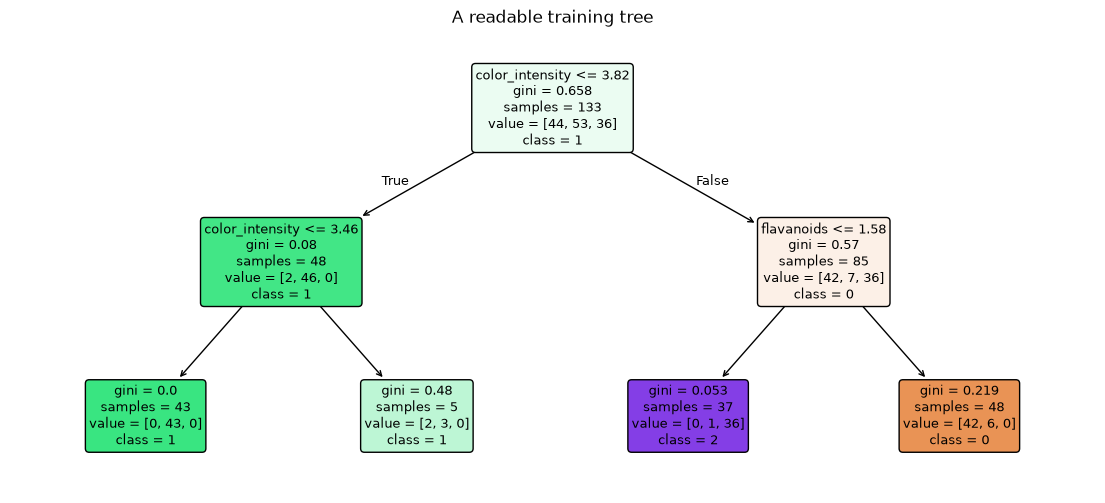

|--- color_intensity <= 3.82
|   |--- color_intensity <= 3.46
|   |   |--- class: 1
|   |--- color_intensity >  3.46
|   |   |--- class: 1
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- class: 2
|   |--- flavanoids >  1.58
|   |   |--- class: 0



In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
small_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=SEED)
small_tree.fit(X_train, y_train)
plt.figure(figsize=(14, 6))
plot_tree(small_tree, feature_names=list(X_train.columns), class_names=["0", "1", "2"],
          filled=True, rounded=True, proportion=False, fontsize=9)
plt.title("A readable training tree"); plt.show()
print(export_text(small_tree, feature_names=list(X_train.columns), max_depth=2))


## 4. Глубина и переобучение

Рассмотрим train score и CV score при увеличении глубины. CV folds фиксированы
и одинаковы для всех вариантов. Значения std по folds показывают нестабильность,
но это не строгий доверительный интервал среднего качества.


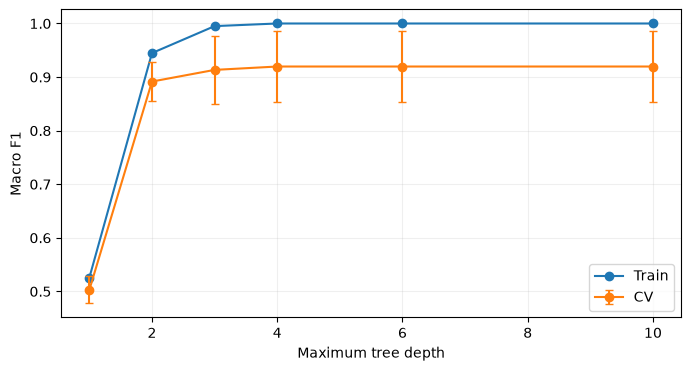

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
depth_rows = []
for depth in [1, 2, 3, 4, 6, 10]:
    score = cross_validate(DecisionTreeClassifier(max_depth=depth, random_state=SEED),
                           X_train, y_train, cv=cv, scoring="f1_macro", return_train_score=True)
    depth_rows.append({"depth": depth, "train": score["train_score"].mean(),
                       "cv": score["test_score"].mean(), "cv_sd": score["test_score"].std()})
depth_table = pd.DataFrame(depth_rows)
plt.plot(depth_table.depth, depth_table.train, "o-", label="Train")
plt.errorbar(depth_table.depth, depth_table.cv, yerr=depth_table.cv_sd, fmt="o-", label="CV", capsize=3)
plt.xlabel("Maximum tree depth"); plt.ylabel("Macro F1"); plt.legend(); plt.show()


## 5. SVM: широкий margin и штраф за нарушения

Для бинарного случая с $y_i\in\{-1,+1\}$ линейный soft-margin SVM решает
$$\min_{w,b}\frac12\|w\|^2+C\sum_i\max(0,1-y_i(w^Tx_i+b)).$$

Большое `C` сильнее штрафует ошибки на train. RBF-ядро
$K(x,x')=\exp(-\gamma\|x-x'\|^2)$ позволяет нелинейную границу.
Большое `gamma` делает влияние отдельного образца более локальным.
Для трёх классов `SVC` использует несколько бинарных задач.


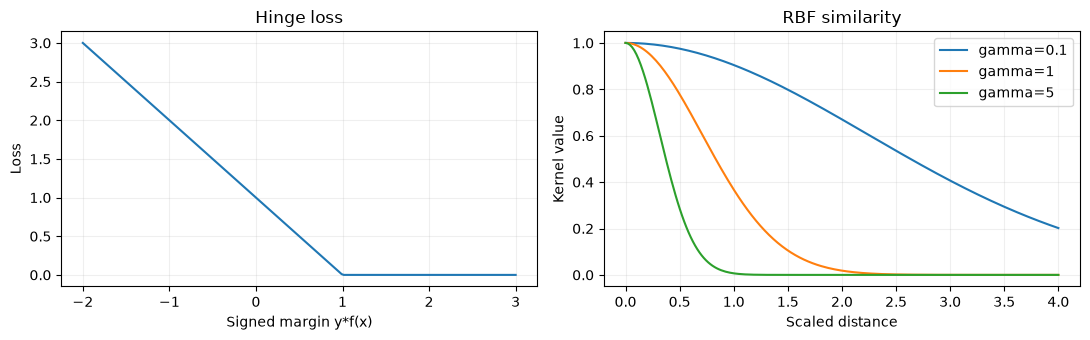

In [7]:
margin = np.linspace(-2, 3, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(margin, np.maximum(0, 1-margin))
axes[0].set(title="Hinge loss", xlabel="Signed margin y*f(x)", ylabel="Loss")
distance = np.linspace(0, 4, 200)
for gamma in [0.1, 1, 5]:
    axes[1].plot(distance, np.exp(-gamma * distance**2), label=f"gamma={gamma}")
axes[1].set(title="RBF similarity", xlabel="Scaled distance", ylabel="Kernel value")
axes[1].legend(); plt.tight_layout(); plt.show()


## 6. Единый план сравнения

Tree не требует StandardScaler для выбора осевых порогов. SVM получает scaler
**внутри** pipeline. Сетки небольшие: задача недели — понять влияние параметров,
а не перебрать тысячи комбинаций на 133 train-наблюдениях.


In [8]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [2, 3, 5, None], "min_samples_leaf": [1, 5, 10]},
    scoring="f1_macro", cv=cv, n_jobs=1)
svm_search = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
    [{"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10]},
     {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.01, 0.1]}],
    scoring="f1_macro", cv=cv, n_jobs=1)
tree_search.fit(X_train, y_train); svm_search.fit(X_train, y_train)
display(pd.DataFrame([
    {"family": "Tree", "best_CV_macro_F1": tree_search.best_score_, "params": tree_search.best_params_},
    {"family": "SVM", "best_CV_macro_F1": svm_search.best_score_, "params": svm_search.best_params_}]))
selected = svm_search if svm_search.best_score_ >= tree_search.best_score_ else tree_search
print("Семейство финальной модели выбрано по CV:", type(selected.best_estimator_).__name__)


,family,best_CV_macro_F1,params
0,Tree,0.927025,"{'max_depth': 5, 'min_samples_leaf': 5}"
1,SVM,0.992528,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker..."


Семейство финальной модели выбрано по CV: Pipeline


## 7. Геометрия на двух признаках — отдельный объяснительный опыт

Картинку нельзя строить как проекцию границы полной 13-мерной модели: это была бы
другая задача. Ниже **две новые учебные модели** обучаются только на `alcohol`
и `flavanoids` train. Эта иллюстрация не участвует в финальном выборе.


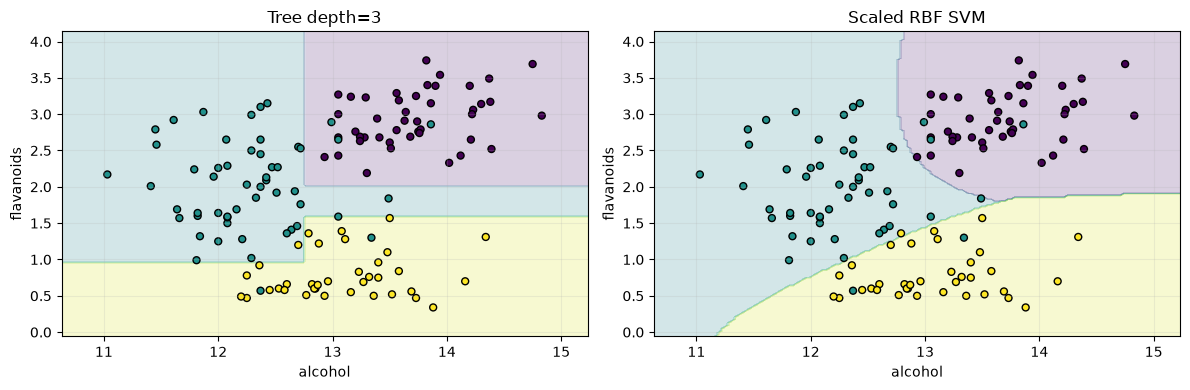

In [9]:
features_2d = ["alcohol", "flavanoids"]
two_dimensional = X_train[features_2d]
models_2d = {"Tree depth=3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
             "Scaled RBF SVM": make_pipeline(StandardScaler(), SVC(C=1, gamma="scale"))}
x_axis = np.linspace(two_dimensional.iloc[:, 0].min()-0.4, two_dimensional.iloc[:, 0].max()+0.4, 160)
y_axis = np.linspace(two_dimensional.iloc[:, 1].min()-0.4, two_dimensional.iloc[:, 1].max()+0.4, 160)
xx, yy = np.meshgrid(x_axis, y_axis)
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=features_2d)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(two_dimensional, y_train)
    ax.contourf(xx, yy, model.predict(grid).reshape(xx.shape), alpha=0.2, cmap="viridis")
    ax.scatter(two_dimensional.iloc[:, 0], two_dimensional.iloc[:, 1], c=y_train, cmap="viridis", edgecolor="k", s=25)
    ax.set(title=name, xlabel=features_2d[0], ylabel=features_2d[1])
plt.tight_layout(); plt.show()


## 8. Финальная оценка выбранной модели

Test использован впервые. Сравним итоговый macro F1 с baseline. Даже если
в этом небольшом holdout ошибок нет, нельзя заключать «100% на любом вине»:
новый регион, прибор или способ измерения могут изменить распределение.


Baseline test macro F1: 0.19047619047619047
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.95      1.00      0.97        18
           2       1.00      0.92      0.96        12

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.98        45
weighted avg       0.98      0.98      0.98        45



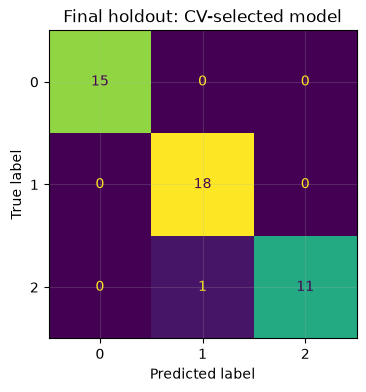

In [10]:
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
prediction = selected.predict(X_test)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline test macro F1:", f1_score(y_test, baseline.predict(X_test), average="macro"))
print(classification_report(y_test, prediction, zero_division=0))
assert prediction.shape == y_test.shape and set(prediction).issubset({0, 1, 2})
ConfusionMatrixDisplay.from_predictions(y_test, prediction, colorbar=False)
plt.title("Final holdout: CV-selected model"); plt.show()


## 9. Проверяем путь одного образца через дерево

Для интерпретации берём первый train-образец. Сумма листовых вероятностей должна
быть 1; число посещённых узлов не больше глубины + 1. Эти проверки относятся
к устройству алгоритма, а не к гарантии качества.


In [11]:
example = X_train.iloc[[0]]
node_ids = small_tree.decision_path(example).indices
leaf_id = small_tree.apply(example)[0]
assert leaf_id in node_ids
assert len(node_ids) <= small_tree.get_depth() + 1
assert np.isclose(small_tree.predict_proba(example).sum(), 1)
print("Узлы пути:", node_ids, "; лист:", leaf_id)
print("Вероятности в листе:", small_tree.predict_proba(example).round(3))


Узлы пути: [0 4 6] ; лист: 6
Вероятности в листе: [[0.875 0.125 0.   ]]


## Вопросы для объяснения вслух

1. Почему глубокое дерево может улучшать train F1 и ухудшать CV F1?
2. Что будет с геометрией SVM при смене единиц одного признака без scaler?
3. Чем `C` отличается от `gamma`? Покажите на hinge loss и RBF-графиках.
4. Почему двумерная граница — отдельная модель, а не полное объяснение 13 признаков?

Источники: [MIT 6.036 materials](https://ocw.mit.edu/courses/6-036-introduction-to-machine-learning-fall-2020/),
[Stanford CS229 notes](https://cs229.stanford.edu/main_notes.pdf),
[Decision Trees](https://scikit-learn.org/stable/modules/tree.html),
[Support Vector Machines](https://scikit-learn.org/stable/modules/svm.html).
